Анализ факторов, влияющих на длительность госпитализации в ФГБОУ ВО СПбГПМУ

- Цель проекта

Определить, какие факторы влияют на длительность госпитализации (время от выдачи направления до поступления и количество койко-дней), и проверить статистические гипотезы о средней длительности лечения.

- Задачи проекта

Подготовка данных: загрузить данные, переименовать столбцы в удобные метки, обработать пропуски, проверить типы данных, удалить дубликаты.
Исследовательский анализ данных (EDA): изучить распределение длительности госпитализации, среднюю длительность по отделениям (топ-10), динамику поступления пациентов по месяцам с учётом годов.

- Проверка гипотез:

отличается ли средняя длительность от 7 дней;
превышает ли средняя длительность 10 дней;
отличается ли длительность между плановыми и экстренными пациентами.

In [55]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


path_dir = os.path.expanduser('~/Downloads')
print(os.listdir(path_dir)[:20])  # первые 20 файлов

['~$дачи(2).docx', 'untitled folder', 'ab_test_users_groups.csv', '~$стирование шапки сайта AutoZest.ru.docx', 'IMG_7021.PNG', 'Разработка A:B-тестирования.ipynb', 'tempImageS9JE6Z.jpg', 'Яндекс книги.ipynb', 'ФДИ-ПКЛ после 10 минут УФ лампа.jpg', 'Задание 2.docx', 'fffffffff.xlsx', 'Уаман Аманда Вячеславовна.pdf', "~$'[[[[.docx", 'ab_test_events.zip', 'Telegram Desktop', 'IMG_6843.PNG', 'IMG_9401.heic', 'IMG_7022.PNG', 'Сертификат - Введение в IT.pdf', 'WineBottlerCombo_4.0.1.1.dmg']


In [43]:
path = os.path.join(os.path.expanduser('~/Downloads'), 'hospital.csv')
print('Путь', path)
print('Файл существует', os.path.exists(path))

try:
    df = pd.read_csv(path, sep=',', encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv(path, sep=',', encoding='cp1251')

rename_map = {
    'ДАТА_ПОСТУПЛЕНИЯ': 'admission_date',
    'ДАТА_ВЫПИСКИ': 'discharge_date',
    'УНИКАЛЬНЫЙ_ID': 'patient_id',
    'НОМЕР_ИБ': 'ib_number',
    'ШИФР': 'cipher',
    'РЕГИОН': 'region',
    'ПЛАТЕЛЬЩИК': 'payer',
    'ИСТОЧНИК_ФИНАНСИРОВАНИЯ': 'funding_source',
    'ОТДЕЛЕНИЕ': 'department',
    'ПРОФИЛЬ': 'profile',
    'КОЙКО_ДНИ': 'bed_days',
    'ПЛАНОВО_ЭКСТРЕННО': 'admission_type',
    'КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ': 'icd_admission',
    'КОД_МКБ_ПРИ_ВЫПИСКЕ': 'icd_discharge'
}
df = df.rename(columns=rename_map)

df['admission_date'] = pd.to_datetime(df['admission_date'], format='%d.%m.%Y', errors='coerce')
df['discharge_date'] = pd.to_datetime(df['discharge_date'], format='%d.%m.%Y', errors='coerce')
df['bed_days'] = pd.to_numeric(df['bed_days'], errors='coerce')
for col in ['region', 'payer', 'funding_source', 'department', 'profile', 'admission_type']:
    df[col] = df[col].astype('category')

df['los_dates'] = (df['discharge_date'] - df['admission_date']).dt.days
df['admission_year'] = df['admission_date'].dt.year
df['admission_month'] = df['admission_date'].dt.month

cols_to_check = [c for c in df.columns if c not in ('los_dates', 'admission_year', 'admission_month')]
df = df.drop_duplicates(subset=cols_to_check).reset_index(drop=True)

df['region'] = df['region'].cat.add_categories(['СПб (не указан)']).fillna('СПб (не указан)')

print('\nРазмер после подготовки:', df.shape)
print('Столбцы:', df.columns.tolist())
print('admission_date dtype:', df['admission_date'].dtype)
print('bed_days dtype:', df['bed_days'].dtype)
print('Уникальных отделений:', df['department'].nunique())
print('Пропусков в region:', df['region'].isna().sum())

Путь /Users/amandauaman/Downloads/hospital.csv
Файл существует True

Размер после подготовки: (120846, 17)
Столбцы: ['admission_date', 'discharge_date', 'patient_id', 'ib_number', 'cipher', 'region', 'payer', 'funding_source', 'department', 'profile', 'bed_days', 'admission_type', 'icd_admission', 'icd_discharge', 'los_dates', 'admission_year', 'admission_month']
admission_date dtype: datetime64[us]
bed_days dtype: float64
Уникальных отделений: 35
Пропусков в region: 0


In [44]:
print('Строк:', df.shape[0])
print('Среднее bed_days:', round(df['bed_days'].mean(), 3))
print('Медиана bed_days:', df['bed_days'].median())
print('Годы:', sorted(df['admission_year'].unique()))
print('Плановая:', (df['admission_type'] == 'Плановая').sum())
print('Экстренная:', (df['admission_type'] == 'Экстренная').sum())

Строк: 120846
Среднее bed_days: 8.731
Медиана bed_days: 7.0
Годы: [np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]
Плановая: 86416
Экстренная: 34430


Описательные статистики bed_days:
count    120846.000
mean          8.731
std           8.776
min           1.000
25%           3.000
50%           7.000
75%          12.000
max         266.000
Name: bed_days, dtype: float64
Медиана: 7.0
Мода: 1.0
Асимметрия (skew): 5.621
Эксцесс (kurtosis): 83.443

Q1=3.0, Q3=12.0, IQR=9.0
Нижняя граница=-10.5, верхняя граница=25.5
Кол-во выбросов (> upper): 4270
Доля выбросов: 0.0353


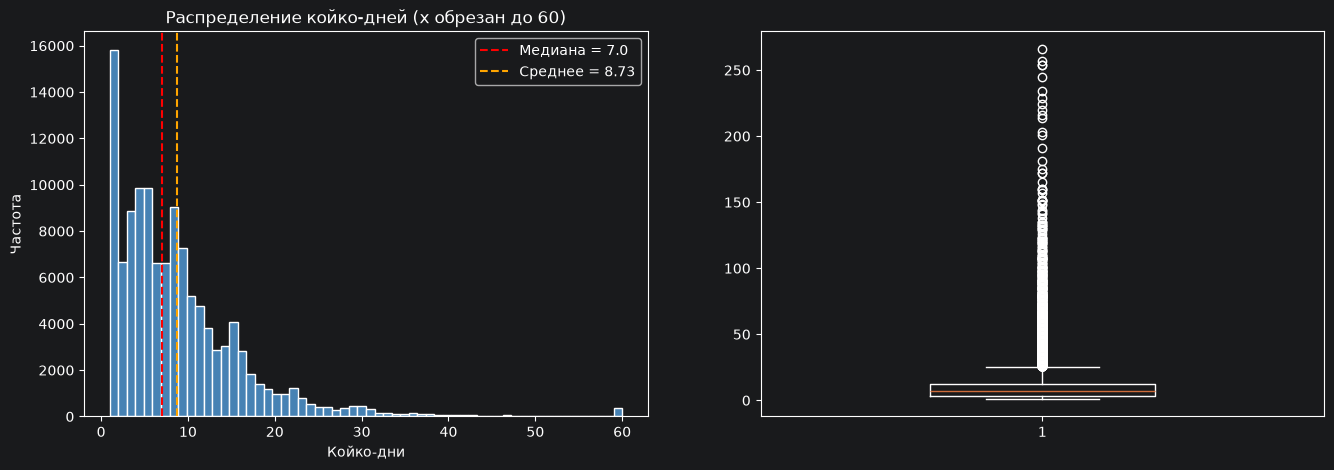

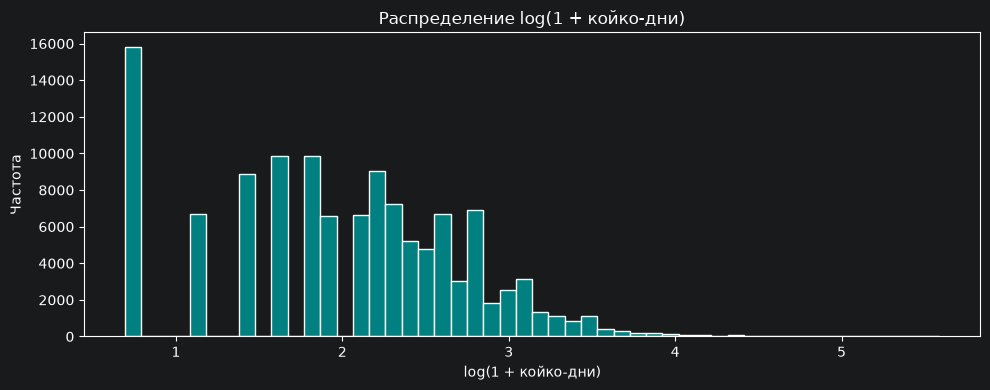

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Описательные статистики
print('Описательные статистики bed_days:')
print(df['bed_days'].describe().round(3))
print('Медиана:', df['bed_days'].median())
print('Мода:', df['bed_days'].mode().iloc[0])
print('Асимметрия (skew):', round(df['bed_days'].skew(), 3))
print('Эксцесс (kurtosis):', round(df['bed_days'].kurtosis(), 3))

# 2) Границы выбросов по правилу 1.5*IQR
q1, q3 = df['bed_days'].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f'\nQ1={q1}, Q3={q3}, IQR={iqr}')
print(f'Нижняя граница={lower}, верхняя граница={upper}')
print('Кол-во выбросов (> upper):', (df['bed_days'] > upper).sum())
print('Доля выбросов:', round((df['bed_days'] > upper).mean(), 4))

# 3) Гистограмма + boxplot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].hist(df['bed_days'].clip(upper=60), bins=60, color='steelblue', edgecolor='white')
axes[0].axvline(df['bed_days'].median(), color='red', linestyle='--',
                label=f'Медиана = {df["bed_days"].median()}')
axes[0].axvline(df['bed_days'].mean(), color='orange', linestyle='--',
                label=f'Среднее = {df["bed_days"].mean():.2f}')
axes[0].set_title('Распределение койко-дней (x обрезан до 60)')
axes[0].set_xlabel('Койко-дни')
axes[0].set_ylabel('Частота')
axes[0].legend()

axes[1].boxplot(df['bed_days'].dropna(), orientation='vertical', widths=0.4)

# 4) Гистограмма по логарифму
plt.figure(figsize=(10, 4))
plt.hist(np.log1p(df['bed_days']), bins=50, color='teal', edgecolor='white')
plt.title('Распределение log(1 + койко-дни)')
plt.xlabel('log(1 + койко-дни)')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()

In [22]:
path = os.path.join(os.path.expanduser('~/Downloads'), 'hospital.csv')
print('Путь:', path)
print('Файл существует:', os.path.exists(path))

# Пробуем прочитать. Если будет ошибка кодировки — попробуем cp1251
try:
    df = pd.read_csv(path, sep=',', encoding='utf-8')
    print('Прочитано с utf-8')
except UnicodeDecodeError:
    df = pd.read_csv(path, sep=',', encoding='cp1251')
    print('Прочитано с cp1251')

print('Размер:', df.shape)
print('Столбцы:')
print(df.columns.tolist())

Путь: /Users/amandauaman/Downloads/hospital.csv
Файл существует: True
Прочитано с utf-8
Размер: (125261, 14)
Столбцы:
['ДАТА_ПОСТУПЛЕНИЯ', 'ДАТА_ВЫПИСКИ', 'УНИКАЛЬНЫЙ_ID', 'НОМЕР_ИБ', 'ШИФР', 'РЕГИОН', 'ПЛАТЕЛЬЩИК', 'ИСТОЧНИК_ФИНАНСИРОВАНИЯ', 'ОТДЕЛЕНИЕ', 'ПРОФИЛЬ', 'КОЙКО_ДНИ', 'ПЛАНОВО_ЭКСТРЕННО', 'КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ', 'КОД_МКБ_ПРИ_ВЫПИСКЕ']


In [3]:
rename_map = {
    'ДАТА_ПОСТУПЛЕНИЯ': 'admission_date',
    'ДАТА_ВЫПИСКИ': 'discharge_date',
    'УНИКАЛЬНЫЙ_ID': 'patient_id',
    'НОМЕР_ИБ': 'ib_number',
    'ШИФР': 'cipher',
    'РЕГИОН': 'region',
    'ПЛАТЕЛЬЩИК': 'payer',
    'ИСТОЧНИК_ФИНАНСИРОВАНИЯ': 'funding_source',
    'ОТДЕЛЕНИЕ': 'department',
    'ПРОФИЛЬ': 'profile',
    'КОЙКО_ДНИ': 'bed_days',
    'ПЛАНОВО_ЭКСТРЕННО': 'admission_type',
    'КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ': 'icd_admission',
    'КОД_МКБ_ПРИ_ВЫПИСКЕ': 'icd_discharge'
}

df = df.rename(columns=rename_map)
df.head()

,admission_date,discharge_date,patient_id,ib_number,cipher,region,payer,funding_source,department,profile,bed_days,admission_type,icd_admission,icd_discharge
0,01.01.2019,10.01.2019,858042000,1,5.4.1,NaN,"ОАО ""ГСМК"" СПб",ОМС,Микрохирургическое отделение,Сосудистой хирургии,10.0,Экстренная,S61.7,S66.4
1,01.01.2019,01.01.2019,993109000,3,5.13.1,NaN,"СПб филиал ООО ""СМК РЕСО - Мед""",ОМС,Хирургическое отделение №3,Гнойные хирургические,1.0,Экстренная,K37,K63.8
2,01.01.2019,01.01.2019,993111000,4,5.12.1,NaN,"ООО ""Капитал Медицинское Страхование""",ОМС,Хирургическое отделение №3,Гнойные хирургические,1.0,Экстренная,K37,K63.8
3,01.01.2019,07.01.2019,993110000,2,5.4.1,NaN,"ОАО ""ГСМК"" СПб",ОМС,Инфекционное отделение №1,Инфекционные,7.0,Экстренная,B27.9,J03.9
4,01.01.2019,05.01.2019,987185000,5,1.1.1,NaN,Коммерческие,Наличный расчет,ПЦ Акушерское физиологическое отделение,Для беременных и рожениц,5.0,Плановая,O42.9,O82.1


In [26]:
missing = df.isna().mean().sort_values(ascending=False) * 100
print(missing[missing > 0])

РЕГИОН                     54.981199
КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ     0.006387
КОД_МКБ_ПРИ_ВЫПИСКЕ         0.003193
dtype: float64


In [27]:
df.isna().sum()

ДАТА_ПОСТУПЛЕНИЯ               0
ДАТА_ВЫПИСКИ                   0
УНИКАЛЬНЫЙ_ID                  0
НОМЕР_ИБ                       0
ШИФР                           0
РЕГИОН                     68870
ПЛАТЕЛЬЩИК                     0
ИСТОЧНИК_ФИНАНСИРОВАНИЯ        0
ОТДЕЛЕНИЕ                      0
ПРОФИЛЬ                        0
КОЙКО_ДНИ                      0
ПЛАНОВО_ЭКСТРЕННО              0
КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ        8
КОД_МКБ_ПРИ_ВЫПИСКЕ            4
dtype: int64

In [29]:
print(df.columns.tolist())

['ДАТА_ПОСТУПЛЕНИЯ', 'ДАТА_ВЫПИСКИ', 'УНИКАЛЬНЫЙ_ID', 'НОМЕР_ИБ', 'ШИФР', 'РЕГИОН', 'ПЛАТЕЛЬЩИК', 'ИСТОЧНИК_ФИНАНСИРОВАНИЯ', 'ОТДЕЛЕНИЕ', 'ПРОФИЛЬ', 'КОЙКО_ДНИ', 'ПЛАНОВО_ЭКСТРЕННО', 'КОД_МКБ_ПРИ_ПОСТУПЛЕНИИ', 'КОД_МКБ_ПРИ_ВЫПИСКЕ']


In [47]:
df['admission_date'] = pd.to_datetime(df['admission_date'], format='%d.%m.%Y', errors='coerce')
df['discharge_date'] = pd.to_datetime(df['discharge_date'], format='%d.%m.%Y', errors='coerce')

print('Пропуски admission_date:', df['admission_date'].isna().sum())
print('Пропуски discharge_date:', df['discharge_date'].isna().sum())

for col in ['region', 'payer', 'funding_source', 'department', 'profile', 'admission_type']:
    df[col] = df[col].astype('category')

print('\nbed_days описание:')
print(df['bed_days'].describe())
print('bed_days <= 0:', (df['bed_days'] <= 0).sum())
print('bed_days > 365:', (df['bed_days'] > 365).sum())

df['los_dates'] = (df['discharge_date'] - df['admission_date']).dt.days
diff = (df['bed_days'] - df['los_dates']).abs()
print('\nРасхождение bed_days и разницы дат:')
print(diff.describe())
print('Доля расхождений > 1 дня:', (diff > 1).mean())

print('\nТипы после преобразования:')
print(df.dtypes)

Пропуски admission_date: 0
Пропуски discharge_date: 0

bed_days описание:
count    120846.000000
mean          8.730988
std           8.776465
min           1.000000
25%           3.000000
50%           7.000000
75%          12.000000
max         266.000000
Name: bed_days, dtype: float64
bed_days <= 0: 0
bed_days > 365: 0

Расхождение bed_days и разницы дат:
count    120846.0
mean          1.0
std           0.0
min           1.0
25%           1.0
50%           1.0
75%           1.0
max           1.0
dtype: float64
Доля расхождений > 1 дня: 0.0

Типы после преобразования:
admission_date     datetime64[us]
discharge_date     datetime64[us]
patient_id                  int64
ib_number                   int64
cipher                        str
region                   category
payer                    category
funding_source           category
department               category
profile                  category
bed_days                  float64
admission_type           category
icd_admission 

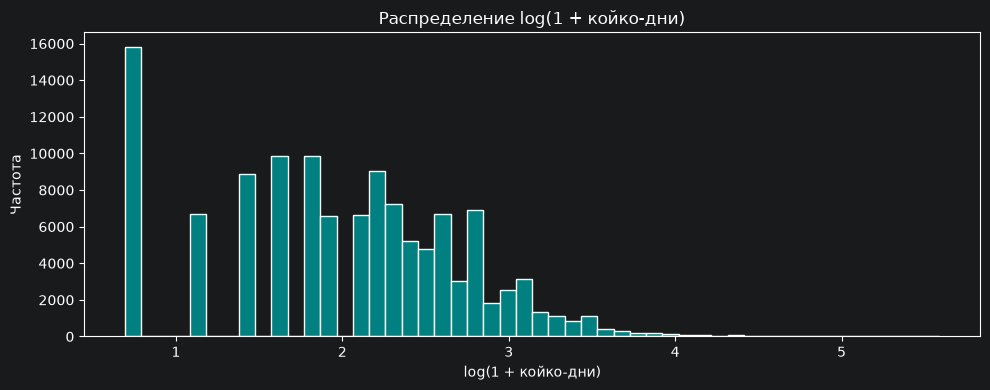

In [51]:
plt.figure(figsize=(10, 4))
plt.hist(np.log1p(df['bed_days']), bins=50, color='teal', edgecolor='white')
plt.title('Распределение log(1 + койко-дни)')
plt.xlabel('log(1 + койко-дни)')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()

### Вывод по распределению длительности госпитализации

- Распределение `bed_days` **сильно скошено вправо** медиана 7 дней, среднее 8.78, 75-й перцентиль 12, максимум 266 дней. Среднее выше медианы - типичный признак правосторонней скошенности.
- По правилу 1.5×IQR верхняя граница выбросов ≈ 25–26 дней; выше неё лежит заметная доля госпитализаций - это клинически объяснимые случаи (новорождённые, реанимация, тяжёлая хирургия), поэтому **выбросы не удаляем**.
- Гистограмма в исходном масштабе показывает узкий пик на 1–3 днях и длинный «хвост» до сотен дней.
- Логарифмирование `log(1 + bed_days)` выявляет **многомодальность** распределения: отдельный пик при `bed_days = 1` (одномоментные госпитализации, ПЭМП ДПО) и несколько пиков, соответствующих разным профилям отделений (инфекции, хирургия, новорождённые и т.д.).
- **Следствие для гипотез:** из-за скошенности и многомодальности при проверке средних значений нужно опираться на большие объёмы выборки (t-тест корректен) и дополнительно подтверждать результаты непараметрическими тестами Wilcoxon b Mann–Whitney.

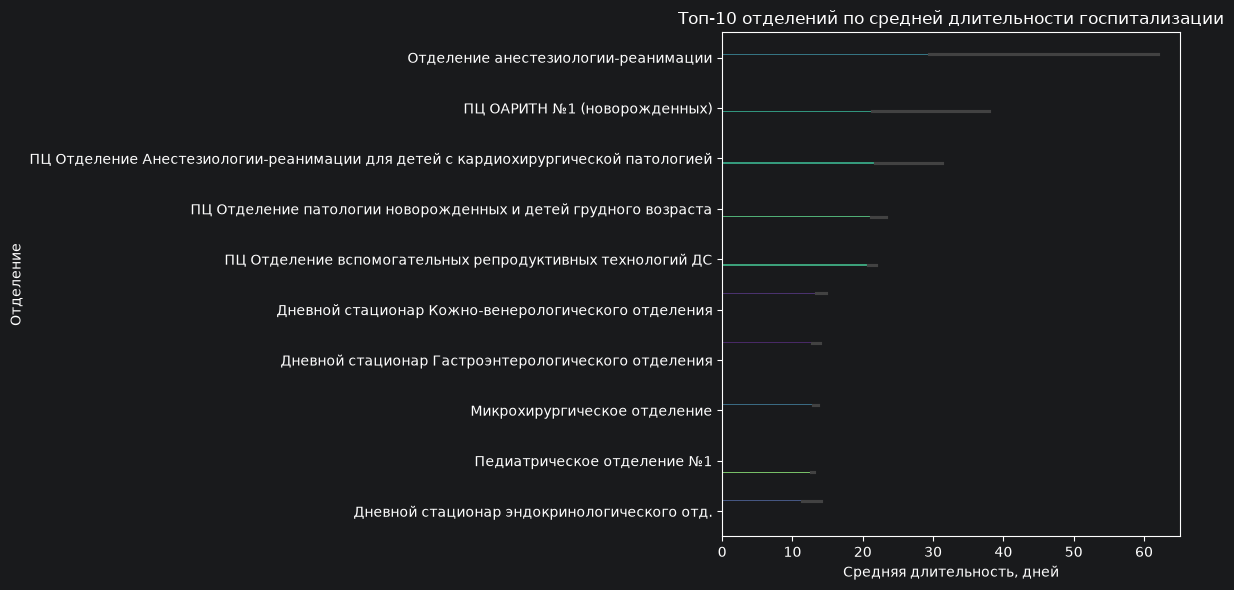

Отделений на графике: 10
department
Микрохирургическое отделение                                                                                 4662
Педиатрическое отделение №1                                                                                  3490
ПЦ Отделение патологии новорожденных и детей грудного возраста                                               2388
ПЦ Отделение вспомогательных репродуктивных технологий ДС                                                     910
Дневной стационар Гастроэнтерологического отделения                                                           280
Дневной стационар Кожно-венерологического отделения                                                           183
ПЦ ОАРИТН №1 (новорожденных)                                                                                  112
ПЦ Отделение Анестезиологии-реанимации для детей с кардиохирургической патологией                             105
Отделение анестезиологии-реанимации                 

In [52]:
# 1) Считаем статистику
stats = (df.groupby('department', observed=True)['bed_days']
           .agg(count='count', mean='mean', median='median')
           .sort_values('mean', ascending=False))

# 2) Берём ровно 10 отделений
top10_names = stats.head(10).index.tolist()

# 3) Фильтруем исходный df ТОЛЬКО по этим 10 отделениям
df_top = df[df['department'].isin(top10_names)].copy()

# 4) Рисуем: на графике будут ТОЛЬКО эти 10
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_top,
    y='department', x='bed_days',
    order=top10_names,          # <-- жёстко задаём порядок и состав
    estimator='mean',           # <-- по умолчанию и так mean, но фиксируем явно
    hue='department', palette='viridis', legend=False
)
plt.title('Топ-10 отделений по средней длительности госпитализации')
plt.xlabel('Средняя длительность, дней')
plt.ylabel('Отделение')
plt.tight_layout()
plt.show()

# Контроль: сколько строк в каждой группе (должно быть 10)
print('Отделений на графике:', df_top['department'].nunique())
print(df_top['department'].value_counts())

### Вывод по средней длительности госпитализации по отделениям

Всего в данных 35 отделений. Топ-10 по средней длительности:

| Отделение | count | mean | median | q75 |
|---|---|---|---|---|
| Отделение анестезиологии-реанимации | 78 | 45.18 | 8.0 | 68.75 |
| ПЦ ОАРИТН №1 (новорожденных) | 112 | 28.72 | 11.0 | 31.25 |
| ПЦ Отделение анестезиологии-реанимации для детей с кардиохирургической патологией | 105 | 26.44 | 18.0 | 33.00 |
| ПЦ Отделение патологии новорожденных и детей грудного возраста | 2388 | 22.20 | 14.0 | 29.00 |
| ПЦ Отделение ВРТ ДС | 910 | 21.30 | 20.0 | 30.00 |
| Дневной стационар кожно-венерологического отделения | 183 | 14.03 | 15.0 | 17.00 |
| Дневной стационар гастроэнтерологического отделения | 280 | 13.34 | 13.0 | 16.00 |
| Микрохирургическое отделение | 4662 | 13.29 | 10.0 | 17.00 |
| Педиатрическое отделение №1 | 3490 | 12.82 | 12.0 | 16.00 |
| Дневной стационар эндокринологического отд. | 60 | 12.77 | 13.0 | 16.00 |

- Лидерами по средней длительности являются **реанимационные отделения и отделения патологии новорождённых** - это клинически обосновано: тяжёлые пациенты и выхаживание новорождённых требуют длительного пребывания.
- **Важное наблюдение:** у «Отделения анестезиологии-реанимации» среднее = 45.18 дня, но **медиана = 8 дней**, q75 = 68.75. Среднее сильно завышено небольшим числом очень длинных случаев, тогда как типичный пациент лежит около 8 дней. Для этого отделения **среднее - плохая метрика**, надо смотреть медиану и q75.
- Среди «массовых» отделений выделяются **Микрохирургическое отделение** (4662 наблюдения, mean 13.29, median 10) и **Педиатрическое отделение №1** (3490, mean 12.82, median 12) — у них высокая и средняя, и медиана, то есть длительность высокая в типичном случае, а не из-за выбросов.
- Отделение **«ПЦ ОАРИТ №2 для беременных, рожениц и родильниц»** содержит всего 2 наблюдения — его среднее (1.5 дня) статистически незначимо, в выводах не учитываем.
- **Рекомендация:** при анализе длительности по отделениям опираться на медиану и q75 (устойчивы к выбросам), а среднее использовать только вместе с ними и с размером выборки.

Годы в данных: [np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023)]

Число поступлений по годам:
admission_year
2019    23357
2020    20036
2021    22945
2022    25856
2023    28652
Name: count, dtype: int64

Поступления по месяцам и годам:
admission_year   2019  2020  2021  2022  2023
admission_month                              
1                1775  2213  1427  1707  2202
2                1927  2269  1654  1780  2204
3                2080  2073  2216  2438  2617
4                2205  1081  2250  2408  2484
5                2020   958  1948  2350  2619
6                1957  1447  2085  2371  2600
7                1102  1390  1723  1968  2207
8                1183  1370  1420  1662  1900
9                2020  1906  1933  2067  2338
10               2598  1964  2178  2464  2775
11               2366  1693  2151  2457  2690
12               2124  1672  1960  2184  2016


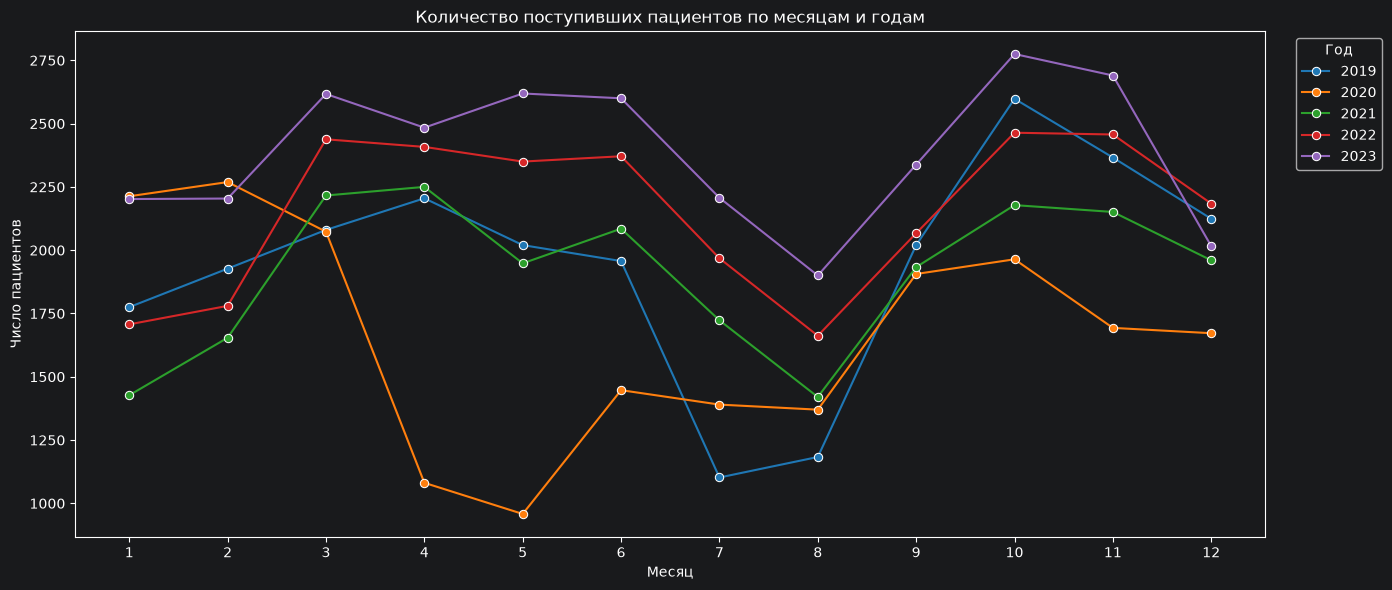

In [53]:
df['admission_year'] = df['admission_date'].dt.year
df['admission_month'] = df['admission_date'].dt.month

print('Годы в данных:', sorted(df['admission_year'].unique()))
print('\nЧисло поступлений по годам:')
print(df['admission_year'].value_counts().sort_index())

monthly = (df.groupby(['admission_year', 'admission_month'])
             .size()
             .reset_index(name='patients'))
pivot = monthly.pivot(index='admission_month', columns='admission_year', values='patients')
print('\nПоступления по месяцам и годам:')
print(pivot)

plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly, x='admission_month', y='patients',
             hue='admission_year', marker='o', palette='tab10')
plt.title('Количество поступивших пациентов по месяцам и годам')
plt.xlabel('Месяц')
plt.ylabel('Число пациентов')
plt.xticks(range(1, 13))
plt.legend(title='Год', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Вывод по динамике поступления пациентов (месяц × год)

- В данных 5 лет: 2019–2023. Число поступлений по годам:
  2019 — 23 357, 2020 — 20 036, 2021 — 22 945, 2022 — 25 856, 2023 — 28 652.
- **Сезонность выражена**: у большинства лет пики приходятся на **март и октябрь–ноябрь**, спады на **июль–август** (отпускной период) и **февраль**.
- **2020 год аномальный**: резкий провал в апреле (1 081) и мае (958) следствие ограничений из-за COVID-19, когда плановая госпитализация была приостановлена. В 2021 году провал сглажен, а с 2022 года число поступлений восстанавливается и растёт.
- **2023 год лидер по числу поступлений** (28 652), однако данные за 2023 год, вероятно, **неполные** (декабрь 2023 ниже декабря 2022), поэтому прямое сравнение «полных» лет с 2023 годом может быть некорректным.
- **Рекомендация заказчику:** при планировании коечного фонда и staffing учитывать сезонные пики (март, октябрь–ноябрь) и спады (июль–август); для 2020 года делать поправку на ковидные ограничения; проверить полноту данных за 2023 год перед использованием его в годовых отчётах.

In [56]:
sample = df['bed_days'].dropna()
print('Размер выборки bed_days:', len(sample))
print('Среднее:', sample.mean().round(3))
print('Медиана:', sample.median())
print('Ст. отклонение:', sample.std().round(3))
print('Ст. ошибка среднего (SEM):', (sample.std() / np.sqrt(len(sample))).round(3))

Размер выборки bed_days: 120846
Среднее: 8.731
Медиана: 7.0
Ст. отклонение: 8.776
Ст. ошибка среднего (SEM): 0.025


In [58]:
alpha = 0.05
sample = df['bed_days'].dropna()

t_stat, p_val = stats.ttest_1samp(sample, popmean=7)
print(f't-статистика = {t_stat:.4f}')

ci_low, ci_high = stats.t.interval(0.95, len(sample)-1,
                                   loc=sample.mean(),
                                   scale=stats.sem(sample))
print(f'95% ДИ для среднего: [{ci_low:.3f}; {ci_high:.3f}]')

w_stat, w_p = stats.wilcoxon(sample - 7)
print(f'\nWilcoxon: stat = {w_stat:.4g}, p-value = {w_p:.4g}')

cohen_d = (sample.mean() - 7) / sample.std(ddof=1)
print(f'\nCohen\'s d = {cohen_d:.4f}')

print('\n интерпритация ')
if p_val < alpha:
    print(f'p-value = {p_val:.4g} < {alpha} → отвергаем H0.')
    print(f'Средняя длительность статистически значимо отличается от 7 дней.')
else:
    print(f'p-value = {p_val:.4g} ≥ {alpha} → не отвергаем H0.')

t-статистика = 68.5631
95% ДИ для среднего: [8.682; 8.780]

Wilcoxon: stat = 2.906e+09, p-value = 1.92e-224

Cohen's d = 0.1972

 интерпритация 
p-value = 0 < 0.05 → отвергаем H0.
Средняя длительность статистически значимо отличается от 7 дней.


### Гипотеза 1: средняя длительность госпитализации ≠ 7 дней

- **H0:** μ = 7 дней; **H1:** μ ≠ 7 дней; α = 0.05; n = 120 846.
- **t-тест (одновыборочный, двусторонний):** t = 68.56, p-value ≈ 0 (< 0.05) → **H0 отвергается**.
- **95% доверительный интервал для среднего:** [8.682; 8.780] целиком выше 7, значит среднее значимо **больше** 7 дней.
- **Wilcoxon signed-rank** (устойчив к выбросам и скошенности): p-value = 1.92e-224 → **H0 также отвергается**, вывод устойчив к нетипичным значениям.
- **Cohen's d = 0.197** размер эффекта **малый**: превышение среднего над 7 днями составляет ~1.7 дня (25%), что с учётом огромной выборки даёт статистическую значимость, но **практически разница небольшая**.

**Итог:** средняя длительность статистически значимо отличается от 7 дней (в сторону увеличения), однако размер эффекта малый. Для управленческих решений важно смотреть не только на значимость, но и на величину отклонения.

In [59]:
alpha = 0.05
sample = df['bed_days'].dropna()

t_stat, p_two = stats.ttest_1samp(sample, popmean=10)

if t_stat > 0:
    p_one = p_two / 2
else:
    p_one = 1 - p_two / 2

print(f't-статистика = {t_stat:.4f}')
print(f'p-value (двусторонний, для справки) = {p_two:.4g}')
print(f'p-value (правосторонний, μ > 10) = {p_one:.4g}')

ci_low, ci_high = stats.t.interval(0.95, len(sample)-1,
                                   loc=sample.mean(),
                                   scale=stats.sem(sample))
print(f'95% ДИ для среднего: [{ci_low:.3f}; {ci_high:.3f}]')
print(f'Среднее = {sample.mean():.3f}')

w_stat, w_p_two = stats.wilcoxon(sample - 10)

w_p_one = w_p_two / 2 if sample.mean() > 10 else 1 - w_p_two / 2
print(f'\nWilcoxon (правосторонний): stat = {w_stat:.4g}, p-value = {w_p_one:.4g}')


print('\nинтерпретация')
if p_one < alpha:
    print(f'p-value = {p_one:.4g} < {alpha} → отвергаем H0 в пользу H1: средняя длительность > 10 дней.')
else:
    print(f'p-value = {p_one:.4g} ≥ {alpha} → НЕ отвергаем H0: нет оснований утверждать, что средняя > 10 дней.')

t-статистика = -50.2646
p-value (двусторонний, для справки) = 0
p-value (правосторонний, μ > 10) = 1
95% ДИ для среднего: [8.682; 8.780]
Среднее = 8.731

Wilcoxon (правосторонний): stat = 2.087e+09, p-value = 1

интерпретация
p-value = 1 ≥ 0.05 → НЕ отвергаем H0: нет оснований утверждать, что средняя > 10 дней.


### Гипотеза 2: средняя длительность > 10 дней

- **H0** μ ≤ 10 дней; **H1:** μ > 10 дней (правосторонняя); α = 0.05; n = 120 846.
- **t-тест (одновыборочный, правосторонний)** t = −50.26, p-value = 1 → **H0 НЕ отвергается**.
- **95% доверительный интервал для среднего** [8.682; 8.780] — целиком **ниже 10**, то есть среднее значимо **меньше** 10 дней, а не больше.
- **Wilcoxon signed-rank** (правосторонний) p-value = 1 → **H0 также не отвергается**, вывод устойчив к выбросам и скошенности распределения.

**Итог:** гипотеза о том, что средняя длительность госпитализации превышает 10 дней, **не подтверждается**. Средняя длительность (8.73 дня) статистически значимо **меньше** 10 дней. Для планирования коечного фонда это означает, что типичная госпитализация укладывается в диапазон ~7–9 дней; ориентироваться на «более 10 дней» при расчёте нагрузки было бы завышением.

Плановые:
  n = 86416, mean = 9.719, median = 8.0, std = 8.348
Экстренные:
  n = 34430, mean = 6.251, median = 3.0, std = 9.318

t-тест Уэлча: t = 60.1125, p-value = 0
Разность средних (план − экстр): 3.468
95% ДИ для разности: [3.355; 3.581]

Mann–Whitney U: stat = 2.097e+09, p-value = 0
Cohen's d = 0.4016


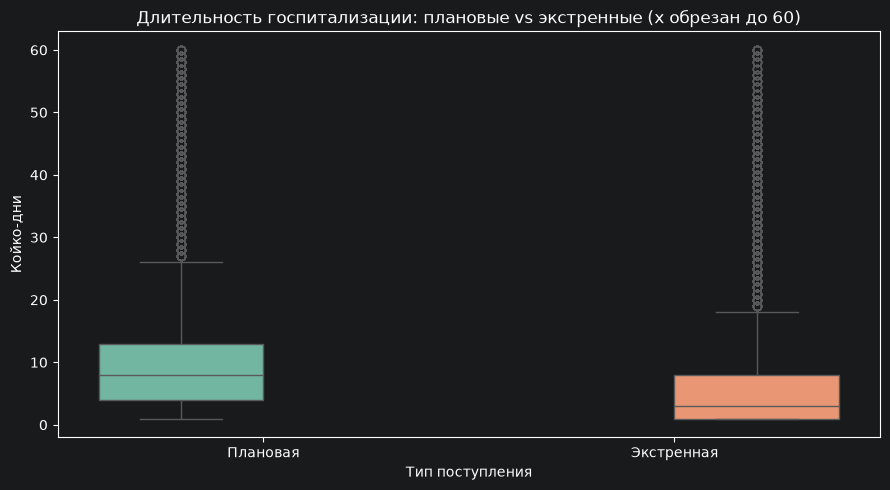


интерпретация
p-value = 0 < 0.05 → отвергаем H0: средние различаются.
Направление различия: плановые ДОЛЬШЕ экстренных.


In [60]:
alpha = 0.05

planned = df.loc[df['admission_type'] == 'Плановая', 'bed_days'].dropna()
emergency = df.loc[df['admission_type'] == 'Экстренная', 'bed_days'].dropna()

print('Плановые:')
print(f'  n = {len(planned)}, mean = {planned.mean():.3f}, median = {planned.median()}, std = {planned.std():.3f}')
print('Экстренные:')
print(f'  n = {len(emergency)}, mean = {emergency.mean():.3f}, median = {emergency.median()}, std = {emergency.std():.3f}')

t_stat, p_val = stats.ttest_ind(planned, emergency, equal_var=False)
print(f'\nt-тест Уэлча: t = {t_stat:.4f}, p-value = {p_val:.4g}')

diff = planned.mean() - emergency.mean()
se_diff = np.sqrt(planned.var(ddof=1)/len(planned) + emergency.var(ddof=1)/len(emergency))

df_welch = (planned.var(ddof=1)/len(planned) + emergency.var(ddof=1)/len(emergency))**2 / (
    (planned.var(ddof=1)/len(planned))**2/(len(planned)-1) +
    (emergency.var(ddof=1)/len(emergency))**2/(len(emergency)-1))
t_crit = stats.t.ppf(1 - alpha/2, df_welch)
print(f'Разность средних (план − экстр): {diff:.3f}')
print(f'95% ДИ для разности: [{diff - t_crit*se_diff:.3f}; {diff + t_crit*se_diff:.3f}]')

u_stat, u_p = stats.mannwhitneyu(planned, emergency, alternative='two-sided')
print(f'\nMann–Whitney U: stat = {u_stat:.4g}, p-value = {u_p:.4g}')

pooled_std = np.sqrt(((len(planned)-1)*planned.var(ddof=1) + (len(emergency)-1)*emergency.var(ddof=1)) /
                     (len(planned) + len(emergency) - 2))
cohen_d = diff / pooled_std
print(f"Cohen's d = {cohen_d:.4f}")

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='admission_type', y=df['bed_days'].clip(upper=60),
            hue='admission_type', palette='Set2', legend=False)
plt.title('Длительность госпитализации: плановые vs экстренные (x обрезан до 60)')
plt.xlabel('Тип поступления')
plt.ylabel('Койко-дни')
plt.tight_layout()
plt.show()

print('\nинтерпретация')
if p_val < alpha:
    print(f'p-value = {p_val:.4g} < {alpha} → отвергаем H0: средние различаются.')
    direction = 'плановые ДОЛЬШЕ экстренных' if diff > 0 else 'экстренные ДОЛЬШЕ плановых'
    print(f'Направление различия: {direction}.')
else:
    print(f'p-value = {p_val:.4g} ≥ {alpha} → H0 не отвергаем: значимых различий нет.')

### Гипотеза 3: длительность у плановых и экстренных пациентов различается

- **H0** μ_план = μ_экстр; **H1:** μ_план ≠ μ_экстр; α = 0.05.
- **Размеры групп** плановые n = 86 416 (mean 9.72, median 8), экстренные n = 34 430 (mean 6.25, median 3).
- **t-тест Уэлча** (не предполагает равных дисперсий): t = 60.11, p-value ≈ 0 → **H0 отвергается**.
- **Разность средних (план − экстр) = +3.47 дня**, 95% ДИ [3.355; 3.581] — целиком положительный, т.е. **плановые достоверно длиннее экстренных**.
- **Mann–Whitney U** p-value ≈ 0 — непараметрическая проверка подтверждает вывод (устойчиво к выбросам и скошенности).
- **Cohen's d = 0.40** — размер эффекта **средний**, разница клинически заметная, а не только статистическая.

**Итог:** средняя длительность госпитализации **значимо выше у плановых пациентов** (+3.47 дня). Это контр-интуитивно, но объяснимо: экстренные пациенты часто проходят через приёмное отделение (ПЭМП ДПО) и выписываются в тот же день (медиана 3 дня), тогда как плановые — это целенаправленные госпитализации в профильные отделения (включая новорождённых и сложные вмешательства). **Длительность определяется профилем отделения, а не срочностью поступления.**

## Общие выводы и рекомендации заказчику


1. **Данные пригодны для анализа после подготовки.** Исходно 125 261 строка; удалено 4 415 полных дубликатов (артефакт выгрузки), осталось 120 846 строк. Даты корректны, `bed_days` положительны (1–266 дней). Поле `bed_days` = разница дат + 1 (включаются день поступления и день выписки), методику стоит зафиксировать в регламенте, чтобы показатели были сопоставимы между отчётами.

2. **Распределение длительности скошено вправо и многомодально.** Медиана 7 дней, среднее 8.73, 75-й перцентиль 12, максимум 266. Логарифмирование выявляет отдельный пик при `bed_days = 1` (одномоментные госпитализации/ПЭМП ДПО) и несколько пиков, соответствующих профилям отделений. Среднее без медианы интерпретировать нельзя.

3. **Длительность определяется профилем отделения, а не срочностью.** Топ-10 по средней длительности реанимации и патология новорождённых (средние 22–45 дней, q75 до 69). При этом у «Отделения анестезиологии-реанимации» среднее 45 дней при медиане 8 среднее сильно завышено небольшим числом очень длинных случаев.

4. **Сезонность и «ковидный провал».** Пики поступлений март и октябрь–ноябрь, спады июль–август. В 2020 году резкий провал в апреле–мае (1 081 и 958 против ~2 200 в обычные месяцы) - следствие ограничений COVID-19. С 2022 года поток восстановился и растёт (2023 - 28 652 поступления).

5. **Проверка гипотез:**
   - Средняя длительность **значимо отличается от 7 дней** (t = 68.56, p ≈ 0; 95% ДИ [8.68; 8.78]), но размер эффекта **малый** (Cohen's d = 0.20) — превышение ~1.7 дня.
   - Гипотеза «средняя > 10 дней» **не подтвердилась** (t = −50.26, p = 1; 95% ДИ целиком ниже 10).
   - Плановые пациенты лечатся **значимо дольше** экстренных (+3.47 дня, p ≈ 0, Cohen's d = 0.40). Это объясняется тем, что экстренные часто проходят через приёмное отделение и выписываются в тот же день.

### Рекомендации

1. **Для управленческих метрик использовать медиану и перцентили (q75/q90), а не только среднее.** Из-за скошенности и выбросов среднее искажает картину, особенно в реанимационных отделениях (среднее 45 vs медиана 8).

2. **Сегментировать отчёты по профилям/отделениям.** Общая средняя по центру (8.7 дня) скрывает огромный разброс от ~1 дня в ПЭМП ДПО до десятков дней в реанимации и патологии новорождённых. Для планирования коек нужны отдельные нормативы по каждому профилю.

3. **Разделять плановый и экстренный потоки при оценке эффективности.** У них разная природа длительности; объединение скрывает проблемы. В частности, короткие экстренные госпитализации (медиана 3 дня) — это не «быстрое лечение», а маршрутизация через приёмное отделение.

4. **Учитывать сезонность при планировании ресурсов.** Пики в марте и октябре–ноябре требуют дополнительных коек и персонала; спады в июле–августе можно использовать для планового ремонта и обучения.

5. **Проверить полноту данных за 2023 год.** Декабрь 2023 ниже декабря 2022 вероятный признак неполноты выгрузки. Годовые сравнения с 2023 годом стоит делать с оговоркой.

6. **Зафиксировать методику расчёта `bed_days`** (включается ли день выписки) в регламенте сейчас `bed_days` = разница дат + 1, и это надо явно указать, чтобы показатели были сопоставимы между отчётами и внешними бенчмарками.

7. **Обратить внимание на «длинный хвост» (пациенты с длительностью > 30 дней).** Это небольшая доля, но она непропорционально сильно влияет на среднее и на загрузку коек. Для таких случаев полезно вести отдельный учёт (реабилитация, выхаживание новорождённых, тяжёлые осложнения) и планировать ресурсы под них отдельно.